# Counter-drone diffusion: findings so far

This notebook collects the project's results to date. It reads the saved results in
`results/`, so it runs in under a minute. To regenerate a result, rerun the script
named in its section (all in `experiments/`).

**Headline findings**

1. **The solvers are validated.** The PDE solver and the simulator match exact answers and each other (Section 1).
2. **Random maneuvering can help or hurt the drone.** It helps a wandering drone and hurts a directed drone facing weak sensors. The switch is a line on the (Pe, Da) map (Section 2).
3. **It is not just speed.** Against a straight drone with the same average travel time, randomness still helps in 72% of the map, by up to 0.19 (Section 3).
4. **The gap between neighbouring sensors sets the switching line** for directed drones. For wandering drones, the whole layout matters (Section 4).
5. **Where to put the ring depends on the drone and on the response distance**, and planning for straight-line drones gives up protection against random ones (Section 5).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from cdd import Scenario, ring_sensors, solve

RES = ROOT / "results"
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

## 0. The model in one cell

A drone moves toward a site at speed v with random maneuvering of strength σ. Sensors
detect it at rate κ(x). The quantity of interest is **u(x), the chance of reaching the
site undetected from x**. It solves D Δu − v ∂u/∂r − κu = 0 with u = 1 at the site.

Lengths are in sensor ranges (ρ = 1) and the drift speed is v = 1. Two numbers then
set everything else:

- **Pe = vρ/D**: how directed the approach is. Here σ = √(2/Pe), so a large Pe means a nearly straight approach.
- **Da = λ₀ρ/v**: how strong the sensors are.

Pe = 2, Da = 1
Drone's best chance from the area edge: u = 0.120 at 90 degrees


/tmp/ipykernel_319/483231996.py:11: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  m = ax.pcolormesh(rr * np.cos(tt), rr * np.sin(tt), sol.u, shading="auto", cmap="viridis")


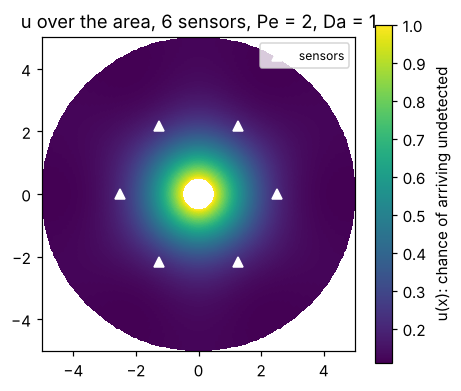

In [2]:
scn = Scenario(r0=0.5, R=5.0, v=1.0, sigma=1.0, lam0=1.0, rho=1.0,
               sensors=ring_sensors(6, 2.5), kernel="gaussian", outer="reflect")
sol = solve(scn, nr=200, ntheta=256)
u_best, angle = sol.worst_entry()
print(f"Pe = {scn.peclet:g}, Da = {scn.detection_number:g}")
print(f"Drone's best chance from the area edge: u = {u_best:.3f} at {np.degrees(angle):.0f} degrees")

# u over the whole area
rr, tt = np.meshgrid(sol.r, sol.theta, indexing="ij")
fig, ax = plt.subplots(figsize=(4.6, 4))
m = ax.pcolormesh(rr * np.cos(tt), rr * np.sin(tt), sol.u, shading="auto", cmap="viridis")
ax.plot(*scn.sensors.T, "w^", ms=7, label="sensors")
ax.set_aspect("equal"); ax.legend(loc="upper right", fontsize=8)
fig.colorbar(m, label="u(x): chance of arriving undetected")
ax.set_title("u over the area, 6 sensors, Pe = 2, Da = 1"); plt.show()

## 1. Validation

*Scripts: `pytest -q` and `experiments/validation_report.py`.*

There are 43 automated checks. The PDE solver matches exact answers to about 2 × 10⁻⁵
and converges at the expected rates (order 2 central, order 1 upwind). All 10 Monte
Carlo comparisons land within 2 standard errors of their reference values.

In [3]:
import json
v = json.loads((RES / "validation.json").read_text())
rows = [{"rung": k, "case": r["case"], "reference": r["reference"], "monte_carlo": r["mc"],
         "half_width_95": r["half_width"], "z": r["z"]}
        for k in ("rung1", "rung2", "rung3", "rung5") for r in v[k]]
display(pd.DataFrame(rows))
c = v["rung4"]
print(f"Fitted convergence orders: central {c['central_order']:.2f}, "
      f"hybrid {c['hybrid_order']:.2f}, upwind {c['upwind_order']:.2f}")

,rung,case,reference,monte_carlo,half_width_95,z
0,rung1,"1D, sigma = 0.5",0.4070,0.4075,0.0007,-1.5452
1,rung1,"1D, sigma = 1.0",0.4809,0.4807,0.0011,0.4436
2,rung1,"1D, sigma = 2.0",0.6065,0.6065,0.0013,0.1118
3,rung2,"no drift, reflecting edge, r = 1.5",0.1505,0.1501,0.0011,0.8370
4,rung2,"no drift, absorbing edge, r = 1.5",0.1502,0.1498,0.0011,0.8644
5,rung3,"radial drift, reflecting edge, r = 2.5",0.3495,0.3488,0.0009,1.4754
6,rung3,"radial drift, absorbing edge, r = 2.5",0.3406,0.3416,0.0010,-1.9802
7,rung5,"4-sensor ring, start r = 4.5, over a sensor",0.1621,0.1620,0.0006,0.1700
8,rung5,"4-sensor ring, start r = 4.5, pi/8 off",0.1836,0.1830,0.0006,1.8669
9,rung5,"4-sensor ring, start r = 4.5, between sensors",0.2054,0.2055,0.0007,-0.1032


Fitted convergence orders: central 1.99, hybrid 1.99, upwind 0.99


## 2. Question 1: does random maneuvering help the drone?

*Script: `experiments/regime_map.py` (120 PDE solves).*

Layout: 6 sensors on a ring of radius 2.5, site radius 0.5, area radius 5. For each
(Pe, Da), the map compares the drone's best chance from any entry point with
random maneuvering against the same drone flying straight.

**Panel (a):** red means randomness helps the drone, blue means it hurts, and the black
line is where it switches. **Panel (b):** how far off the straight-line shortcut is
(question 2).

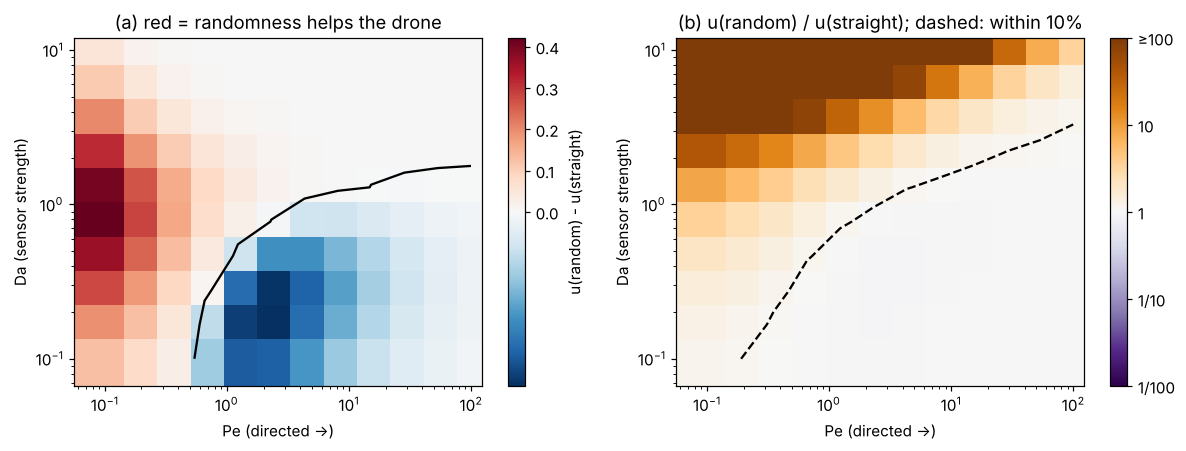

Randomness helps in 62% of the grid; largest help +0.421, largest harm -0.048


In [4]:
rm = pd.read_csv(RES / "regime_map.csv")
pes, das = np.sort(rm.Pe.unique()), np.sort(rm.Da.unique())
grid = lambda df, col: df.pivot(index="Pe", columns="Da", values=col).loc[pes, das].to_numpy()
delta, ratio = grid(rm, "delta"), grid(rm, "ratio")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
m1 = a1.pcolormesh(pes, das, delta.T, shading="nearest", cmap="RdBu_r",
                   norm=TwoSlopeNorm(0, delta.min(), delta.max()))
a1.contour(pes, das, delta.T, levels=[0], colors="k")
fig.colorbar(m1, ax=a1, label="u(random) - u(straight)")
a1.set_title("(a) red = randomness helps the drone")
lr = np.clip(np.log10(ratio), -2, 2)
m2 = a2.pcolormesh(pes, das, lr.T, shading="nearest", cmap="PuOr_r", norm=TwoSlopeNorm(0, -2, 2))
a2.contour(pes, das, lr.T, levels=np.log10([0.9, 1.1]), colors="k", linestyles="--")
cb = fig.colorbar(m2, ax=a2, ticks=[-2, -1, 0, 1, 2]); cb.ax.set_yticklabels(["1/100", "1/10", "1", "10", "≥100"])
a2.set_title("(b) u(random) / u(straight); dashed: within 10%")
for a in (a1, a2):
    a.set(xscale="log", yscale="log", xlabel="Pe (directed →)", ylabel="Da (sensor strength)")
plt.tight_layout(); plt.show()
print(f"Randomness helps in {100 * (delta > 0).mean():.0f}% of the grid; "
      f"largest help {delta.max():+.3f}, largest harm {delta.min():+.3f}")

### Check: does the simulator agree?

*Script: `experiments/regime_spotcheck.py`.*

At six points on the map, the simulator starts drones from the PDE's worst-case entry
point. All six agree with the PDE. At every point, the simulator's 95% interval excludes
the straight-line value, so it shows the same helps-or-hurts sign on its own.

In [5]:
display(pd.read_csv(RES / "regime_spotcheck.csv"))

,Pe,Da,map_says,u_pde,u_monte_carlo,half_width_95,z,u_straight,sign_clear
0,0.10,0.77,helps (strong),0.5970,0.5968,0.0023,0.2060,0.1759,True
1,0.19,1.29,helps (strong),0.3163,0.3185,0.0024,-1.7907,0.0544,True
2,2.31,0.17,hurts (strongest),0.6334,0.6332,0.0014,0.3408,0.6814,True
3,1.23,0.28,hurts,0.4951,0.4942,0.0020,0.8626,0.5316,True
4,0.66,0.28,near the boundary,0.5385,0.5392,0.0022,-0.6981,0.5316,True
5,4.33,0.77,near the boundary,0.1662,0.1661,0.0010,0.1549,0.1759,True


## 3. Is it randomness, or just speed?

*Script: `experiments/regime_equal_time.py`.*

At low Pe a random drone reaches the site faster on average than a straight one, so
part of the "help" in Section 2 is speed. Here each random drone is compared with a
straight drone that takes the **same average time**. Most of the help survives, and the
harm at moderate Pe stays.

Mean travel time from the edge with no sensors (straight flight: 4.50):
Pe
0.1000      1.85
0.1874      2.94
0.3511      4.17
0.6579      5.02
1.2328      5.18
2.3101      4.98
4.3288      4.78
8.1113      4.65
15.1991     4.58
28.4804     4.55
53.3670     4.52
100.0000    4.51


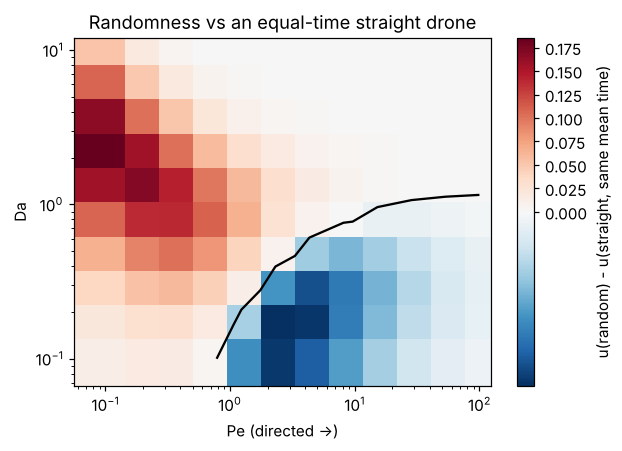

Randomness helps in 72% of the grid; largest help +0.185


In [6]:
eq = pd.read_csv(RES / "regime_equal_time.csv")
times = eq.groupby("Pe").mean_time.first()
print("Mean travel time from the edge with no sensors (straight flight: 4.50):")
print(times.round(2).to_string())
d_eq = grid(eq, "delta_equal_time")
fig, ax = plt.subplots(figsize=(5.8, 4.2))
m = ax.pcolormesh(pes, das, d_eq.T, shading="nearest", cmap="RdBu_r",
                  norm=TwoSlopeNorm(0, d_eq.min(), d_eq.max()))
ax.contour(pes, das, d_eq.T, levels=[0], colors="k")
fig.colorbar(m, label="u(random) - u(straight, same mean time)")
ax.set(xscale="log", yscale="log", xlabel="Pe (directed →)", ylabel="Da",
       title="Randomness vs an equal-time straight drone")
plt.tight_layout(); plt.show()
print(f"Randomness helps in {100 * (d_eq > 0).mean():.0f}% of the grid; largest help {d_eq.max():+.3f}")

## 4. Does the result depend on the layout?

*Scripts: `experiments/regime_layouts.py` and `experiments/regime_gap_test.py`.*

The switching line keeps its shape across layouts, but its position depends on the
**gap between neighbouring sensors**, g = 2a·sin(π/K). In the gap test, each color is one
gap built three different ways. For directed drones (right side), lines with the same
color nearly overlap, so the gap alone sets the switch. For wandering drones (left side),
they spread out, so the ring's size and sensor count also matter.

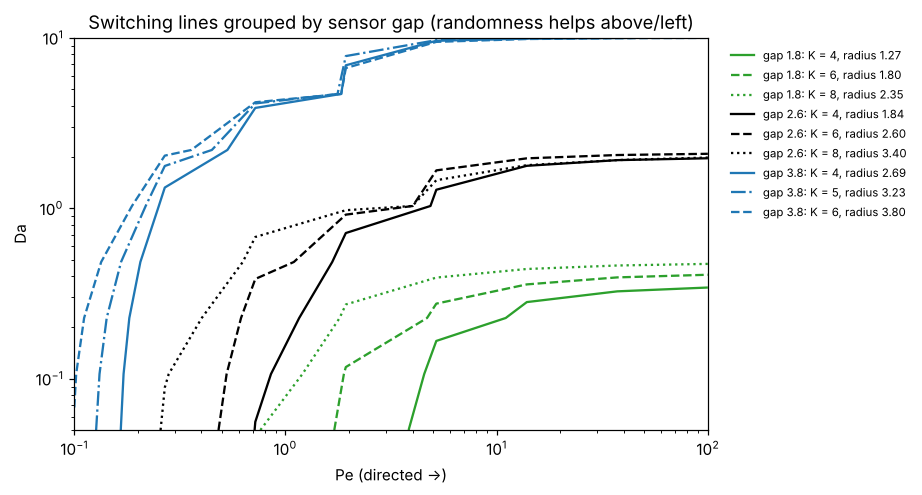

,gap,layouts agree on helps/hurts
0,1.8,0.9375
1,2.6,0.9375
2,3.8,0.9844


In [7]:
gt = pd.read_csv(RES / "regime_gap_test.csv")
gp, gd = np.sort(gt.Pe.unique()), np.sort(gt.Da.unique())
colors, styles = {1.8: "C2", 2.6: "k", 3.8: "C0"}, {4: "-", 5: "-.", 6: "--", 8: ":"}
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for (gap, k), df in gt.groupby(["gap", "K"]):
    z = df.pivot(index="Pe", columns="Da", values="delta").loc[gp, gd].to_numpy()
    if z.min() < 0 < z.max():
        ax.contour(gp, gd, z.T, levels=[0], colors=colors[gap], linestyles=styles[k])
    ax.plot([], [], color=colors[gap], ls=styles[k],
            label=f"gap {gap}: K = {k}, radius {df.ring_radius.iloc[0]:.2f}")
ax.set(xscale="log", yscale="log", xlabel="Pe (directed →)", ylabel="Da",
       title="Switching lines grouped by sensor gap (randomness helps above/left)")
ax.legend(fontsize=7.5, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

agree = []
for gap, df in gt.groupby("gap"):
    signs = np.array([g.sort_values(["Pe", "Da"]).delta.to_numpy() > 0 for _, g in df.groupby("K")])
    agree.append({"gap": gap, "layouts agree on helps/hurts": (signs.all(0) | (~signs).all(0)).mean()})
display(pd.DataFrame(agree))

## 5. Question 3: where should the ring go?

*Script: `experiments/q3_best_ring.py`.*

A detection only helps if it comes before the drone is within a **response distance d**
of the site, the distance needed to react. "Arrival" therefore means reaching r = d.
Without this, the best ring presses against the site, where detection comes too late.

For each d, number of sensors K and drone type, the script finds the ring radius that
minimizes the drone's best chance. It compares that with the radius a planner would pick
by assuming straight-line drones. The cost column is how much more often the drone gets
through with the straight-line pick.

,response_distance,K,drone,best_radius,best_at_scan_edge,u_worst_at_best,straight_line_radius,u_random_at_straight_choice,cost_of_straight_choice
0,1.0,3,wandering (Pe = 0.5),2.3764,False,0.5770,0.4281,0.7237,0.1467
1,1.0,3,mixed (Pe = 2),1.4386,False,0.4427,0.4281,0.4979,0.0551
2,1.0,3,directed (Pe = 20),0.5806,False,0.3280,0.4281,0.3291,0.0011
3,1.0,4,wandering (Pe = 0.5),2.6418,False,0.4527,0.9418,0.5962,0.1436
4,1.0,4,mixed (Pe = 2),1.8426,False,0.3018,0.9418,0.3555,0.0537
5,1.0,4,directed (Pe = 20),1.1119,False,0.2079,0.9418,0.2097,0.0018
6,1.0,5,wandering (Pe = 0.5),2.8206,False,0.3679,1.2154,0.4927,0.1248
7,1.0,5,mixed (Pe = 2),2.0703,False,0.2164,1.2154,0.2576,0.0412
8,1.0,5,directed (Pe = 20),1.3914,False,0.1309,1.2154,0.1324,0.0015
9,1.0,6,wandering (Pe = 0.5),2.9355,False,0.3074,1.3635,0.4170,0.1096


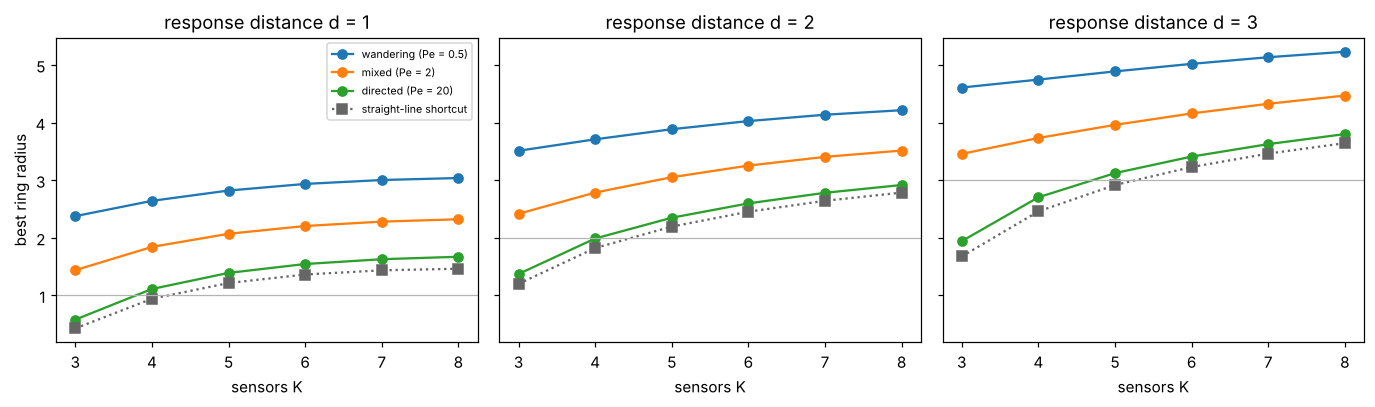

In [8]:
q3 = pd.read_csv(RES / "q3_best_ring.csv")
show = q3[["response_distance", "K", "drone", "best_radius", "best_at_scan_edge",
           "u_worst_at_best", "straight_line_radius", "u_random_at_straight_choice",
           "cost_of_straight_choice"]]
display(show)

ds = sorted(q3.response_distance.unique())
fig, axes = plt.subplots(1, len(ds), figsize=(4.2 * len(ds), 3.8), sharey=True, squeeze=False)
for ax, d in zip(axes[0], ds):
    sub = q3[q3.response_distance == d]
    for n, (drone, df) in enumerate(sub.groupby("drone", sort=False)):
        ax.plot(df.K, df.best_radius, "o-", color=f"C{n}", label=drone)
    first = sub[sub.drone == sub.drone.iloc[0]]
    ax.plot(first.K, first.straight_line_radius, "s:", color="0.4", label="straight-line shortcut")
    ax.axhline(d, color="0.7", lw=0.8)
    ax.set(title=f"response distance d = {d:g}", xlabel="sensors K")
axes[0, 0].set_ylabel("best ring radius"); axes[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 6. Open items

- **Question 3, part 2:** let the sensors move freely instead of forcing a ring, then build the ±25% sensitivity table for range and detection rate.
- **Question 4:** sensors that switch on and off at random (downtime).
- **Real-world numbers:** drone speeds, sensor ranges and detection rates from published sources, to turn Pe and Da into real systems.
- **Final figures:** rerun the maps on finer grids. The layout and gap tests used 8 × 6 and 8 × 8 grids, so their lines are jagged.